## 0. Persiapan Lingkungan dan Dataset

In [ ]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [ ]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan langsung memberi pesan jelas bila gagal."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd)
        plt.axis("off")
    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat.
    Makin besar KB, makin mudah bercak dipisahkan dari daun sehat."""
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)


def statistik(gray):
    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}


Writing src/utils_cv.py


In [ ]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [ ]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


## Bagian 5. Integrasi: Rangkaian Praproses SIMUTEH
### Kode 5.1 Modul `src/praproses.py` (lengkap)

In [ ]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,            # sampling: lebar citra kerja (piksel)
    "gamma": "auto",         # angka tetap, atau "auto" (dipilih dari statistik kanal V)
    "clahe_clip": 1.0,       # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 4,
    "clahe_otomatis": True,  # True: CLAHE hanya bila cahaya terdeteksi tidak merata
    "batas_tidak_rata": 0.65,
    "penapis": "median",     # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,          # 0 berarti tanpa penajaman
}


def gamma_otomatis(img_bgr):
    """Memilih gamma dari statistik kanal V (aturan hasil analisis Bagian 3):
    terang (rerata V > 210) -> 1.6; kontras rendah (simp. baku V < 20) -> 1.0;
    gelap (persentil 95 V < 200) -> 0.6; selain itu -> 1.0."""
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2]
    if v.mean() > 210:
        return 1.6
    if v.std() < 20:
        return 1.0
    if np.percentile(v, 95) < 200:
        return 0.6
    return 1.0


def indeks_tidak_rata(img_bgr):
    """Perkiraan ketidakrataan cahaya: citra dibagi 4 x 4 blok, kecerahan tiap blok
    diwakili persentil 90 kanal V (umumnya latar nampan), lalu dihitung
    (maks - min) / rerata. Nilai besar berarti ada bagian yang jauh lebih teduh."""
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2].astype(float)
    h, w = v.shape
    blok = [np.percentile(v[i*h//4:(i+1)*h//4, j*w//4:(j+1)*w//4], 90)
            for i in range(4) for j in range(4)]
    return (max(blok) - min(blok)) / np.mean(blok)


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}
    # 1. ubah ukuran, rasio aspek tetap
    h, w = img_bgr.shape[:2]
    img = cv2.resize(img_bgr, (p["lebar"], int(round(h * p["lebar"] / w))),
                     interpolation=cv2.INTER_AREA)
    # 2. koreksi gamma dengan lookup table
    g = gamma_otomatis(img) if p["gamma"] == "auto" else float(p["gamma"])
    if g != 1.0:
        lut = np.array([255 * (i / 255) ** g for i in range(256)])
        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))
    # 3. CLAHE hanya pada kanal V agar warna tidak bergeser
    pakai_clahe = p["clahe_clip"] > 0
    if pakai_clahe and p["clahe_otomatis"]:
        pakai_clahe = indeks_tidak_rata(img) > p["batas_tidak_rata"]
    if pakai_clahe:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    # 4. redam derau
    k = p["kernel"]
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # 5. tajamkan (unsharp masking) bila diminta
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing ../src/praproses.py


### Kode 5.2 Evaluasi: membandingkan beberapa konfigurasi pada kanal terpilih

Kanal dievaluasi: R
Rerata KB sesudah praproses per konfigurasi


kondisi,bayangan,gelap,kontras_rendah,normal,terang
konfigurasi,,,,,
"A. contoh petunjuk (CLAHE 2/8 selalu, median 3)",8.34,14.70,5.11,9.83,6.44
B. median 3 saja,6.08,14.91,7.71,13.02,10.62
C. CLAHE 1/4 selalu + median 3,7.82,15.11,7.06,11.83,9.05
D. gamma auto + CLAHE 1/4 selalu + median 3,7.82,11.09,7.06,11.83,11.28
E. FINAL: gamma auto + CLAHE otomatis + median 3,7.82,10.91,7.71,13.02,12.03
(sebelum praproses),4.93,8.40,3.69,8.00,6.17


Rerata dI sesudah praproses per konfigurasi


kondisi,bayangan,gelap,kontras_rendah,normal,terang
konfigurasi,,,,,
"A. contoh petunjuk (CLAHE 2/8 selalu, median 3)",82.7,106.7,49.1,99.3,80.3
B. median 3 saja,66.4,89.8,34.6,94.6,73.3
C. CLAHE 1/4 selalu + median 3,72.9,93.0,41.4,92.2,74.1
D. gamma auto + CLAHE 1/4 selalu + median 3,72.9,95.3,41.4,92.2,90.7
E. FINAL: gamma auto + CLAHE otomatis + median 3,72.9,95.7,34.6,94.6,92.1


{
  "lebar": 640,
  "gamma": "auto",
  "clahe_clip": 1.0,
  "clahe_tile": 4,
  "clahe_otomatis": true,
  "batas_tidak_rata": 0.65,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


,KB_sebelum,KB_sesudah,Perubahan (%)
kondisi,,,
bayangan,4.93,7.82,58.78
gelap,8.40,10.91,29.89
kontras_rendah,3.69,7.71,109.09
normal,8.00,13.02,62.70
terang,6.17,12.03,94.99


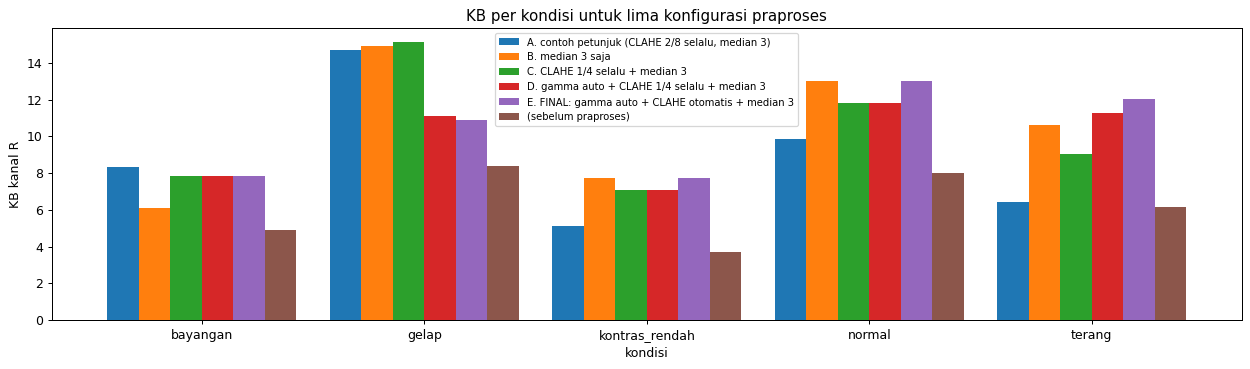

Gamma terpilih per kondisi:


gamma,0.6,1.0,1.6
kondisi_cahaya,,,
bayangan,0,12,0
gelap,9,3,0
kontras_rendah,0,12,0
normal,0,12,0
terang,0,0,12


Indeks ketidakrataan cahaya dan keputusan CLAHE:


,indeks_min,indeks_maks,jumlah_CLAHE
kondisi_cahaya,,,
bayangan,0.790,0.911,12
gelap,0.100,0.626,0
kontras_rendah,0.086,0.181,0
normal,0.107,0.414,0
terang,0.113,0.196,0


In [ ]:
import importlib, praproses as pp
importlib.reload(pp)
KANAL = {"B": 0, "G": 1, "R": 2}.get(KANAL_TERBAIK, 2)
print("Kanal dievaluasi:", KANAL_TERBAIK if KANAL_TERBAIK in "BGR" else "R")

konfigurasi = {
    "A. contoh petunjuk (CLAHE 2/8 selalu, median 3)": {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8, "clahe_otomatis": False, "penapis": "median", "kernel": 3},
    "B. median 3 saja":                         {"gamma": 1.0, "clahe_clip": 0, "penapis": "median", "kernel": 3},
    "C. CLAHE 1/4 selalu + median 3":           {"gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": False, "penapis": "median", "kernel": 3},
    "D. gamma auto + CLAHE 1/4 selalu + median 3": {"gamma": "auto", "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": False, "penapis": "median", "kernel": 3},
    "E. FINAL: gamma auto + CLAHE otomatis + median 3": {"gamma": "auto", "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": True, "penapis": "median", "kernel": 3},
}
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    im, m_d, m_b = muat(d.nama_file)
    kb0 = kontras_bercak(im[:, :, KANAL], m_d, m_b); di0 = selisih_rerata(im[:, :, KANAL], m_d, m_b)
    for nk, par in konfigurasi.items():
        out = pp.praproses(im, par)
        baris.append([nk, d.kondisi_cahaya, kb0, kontras_bercak(out[:, :, KANAL], m_d, m_b),
                      di0, selisih_rerata(out[:, :, KANAL], m_d, m_b)])
ev = pd.DataFrame(baris, columns=["konfigurasi", "kondisi", "KB_sebelum", "KB_sesudah", "dI_sebelum", "dI_sesudah"])
banding = ev.pivot_table(index="konfigurasi", columns="kondisi", values="KB_sesudah").round(2)
banding.loc["(sebelum praproses)"] = ev.groupby("kondisi").KB_sebelum.mean().round(2)
print("Rerata KB sesudah praproses per konfigurasi"); display(banding)
print("Rerata dI sesudah praproses per konfigurasi"); display(ev.pivot_table(index="konfigurasi", columns="kondisi", values="dI_sesudah").round(1))

PARAM_FINAL = konfigurasi["E. FINAL: gamma auto + CLAHE otomatis + median 3"]
pp.simpan_param(PARAM_FINAL)
print(open("../hasil/param_praproses.json").read())

final = ev[ev.konfigurasi.str.startswith("E.")].groupby("kondisi")[["KB_sebelum", "KB_sesudah"]].mean()
final["Perubahan (%)"] = 100 * (final.KB_sesudah - final.KB_sebelum) / final.KB_sebelum
final = final.round(2); final.to_csv("../hasil/b5_evaluasi.csv"); display(final)

banding.T.plot.bar(figsize=(14, 4.2), rot=0, width=0.85)
plt.ylabel("KB kanal " + KANAL_TERBAIK); plt.title("KB per kondisi untuk lima konfigurasi praproses")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("../hasil/b5_banding.png", bbox_inches="tight"); plt.show()

# keputusan otomatis (gamma dan CLAHE) pada setiap kondisi
cit = {n: baca(f"../data/sintetis/citra/{n}") for n in label.nama_file}
pilih = label.assign(gamma=[pp.gamma_otomatis(cit[n]) for n in label.nama_file],
                     indeks=[pp.indeks_tidak_rata(cit[n]) for n in label.nama_file])
pilih["CLAHE"] = pilih.indeks > 0.65
print("Gamma terpilih per kondisi:"); display(pilih.groupby("kondisi_cahaya").gamma.value_counts().unstack(fill_value=0))
print("Indeks ketidakrataan cahaya dan keputusan CLAHE:")
display(pilih.groupby("kondisi_cahaya").agg(indeks_min=("indeks", "min"), indeks_maks=("indeks", "max"),
                                             jumlah_CLAHE=("CLAHE", "sum")).round(3))

### Langkah 5.3 Uji bercak palsu pada kelas sehat

In [ ]:
baris, contoh = [], {}
for _, d in label[label.kelas == "sehat"].iterrows():
    im, m_d, _ = muat(d.nama_file)
    out = pp.praproses(im, PARAM_FINAL)
    m = m_d > 0
    a, b_ = im[:, :, KANAL].astype(float), out[:, :, KANAL].astype(float)
    def pencilan(x):   # persen piksel daun yang lebih terang dari rerata + 3 simpangan baku
        return 100 * (x[m] > x[m].mean() + 3 * x[m].std()).mean()
    baris.append([d.kondisi_cahaya, a[m].std(), b_[m].std(), pencilan(a), pencilan(b_), a[m].mean(), b_[m].mean()])
    contoh.setdefault(d.kondisi_cahaya, (d.nama_file, im, out, m))
uji = pd.DataFrame(baris, columns=["kondisi", "sd sebelum", "sd sesudah", "% pencilan sebelum",
                                   "% pencilan sesudah", "rerata daun sebelum", "rerata daun sesudah"])
uji = uji.groupby("kondisi").mean().round(2); uji.to_csv("../hasil/b5_uji_sehat.csv"); display(uji)

daftar, judul = [], []
for kond, (nm, im, out, m) in contoh.items():
    b_ = out[:, :, KANAL].astype(float)
    tanda = out.copy()
    tanda[m & (b_ > b_[m].mean() + 3 * b_[m].std())] = (0, 0, 255)     # pencilan diberi warna merah
    daftar += [im, out, tanda]; judul += [f"{nm[:7]} {kond}", "sesudah praproses", "pencilan (merah)"]
tampil(daftar, judul, baris=5, ukuran=(14, 20))
plt.savefig("../hasil/b5_uji_sehat.png", bbox_inches="tight"); plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Langkah 5.4 Justifikasi dan diagram rangkaian praproses final

,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,1. Ubah ukuran,"lebar 640 px, INTER_AREA",Lembar hitung 2.1: konvolusi 5x5 pada 640x480 ...,"Terlalu kecil: bercak ringan hilang (Kode 2.2,..."
1,2. Koreksi gamma,"auto: 0,6 gelap; 1,6 terang; 1,0 lainnya",Satu gamma tetap tidak cocok untuk semua kondi...,Gamma terlalu besar menggelapkan daun sampai j...
2,3. CLAHE kanal V,"clip 1,0; tile 4 x 4; hanya bila indeks ketida...",Kode 3.3: clip 1 tile 4 memberi KB tertinggi p...,Clip besar atau CLAHE pada semua citra memperk...
3,4. Redam derau,median 3 x 3,Kode 4.2: median 3 terbaik untuk garam-merica ...,Kernel 9 ke atas menghapus bercak ringan (dI t...
4,5. Tajamkan,tidak dipakai (k = 0),Kode 4.4: penajaman memperkuat derau di latar;...,"Bila dipakai sebelum redam derau, derau diperkuat"


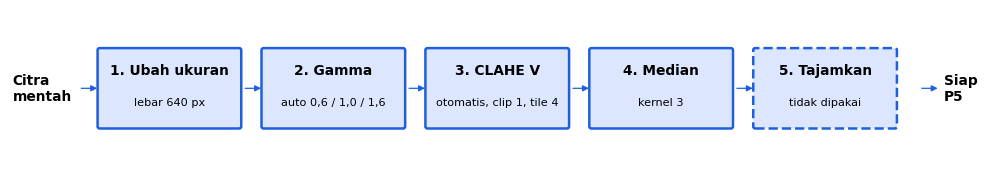

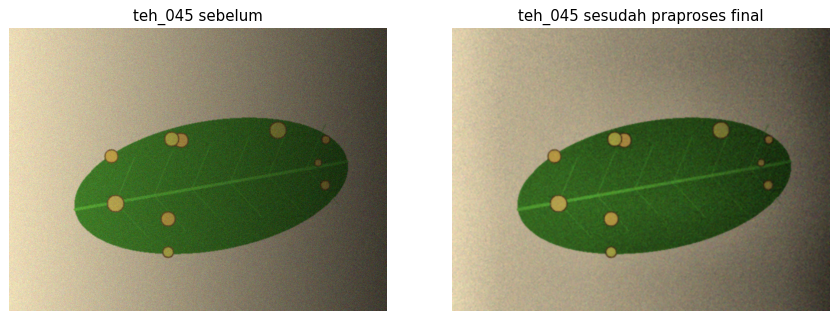

In [ ]:
justifikasi = pd.DataFrame([
 ["1. Ubah ukuran", "lebar 640 px, INTER_AREA",
  "Lembar hitung 2.1: konvolusi 5x5 pada 640x480 39 kali lebih ringan daripada 4000x3000; bercak 5 mm tetap >= 10 px bila dipotret dari jarak <= 23 cm",
  "Terlalu kecil: bercak ringan hilang (Kode 2.2, fx 0,1 dan 0,05)"],
 ["2. Koreksi gamma", "auto: 0,6 gelap; 1,6 terang; 1,0 lainnya",
  "Satu gamma tetap tidak cocok untuk semua kondisi (Kode 3.2, Langkah 3.5); aturan otomatis memilih gamma yang benar untuk citra gelap dan terang",
  "Gamma terlalu besar menggelapkan daun sampai jenuh, KB naik semu"],
 ["3. CLAHE kanal V", "clip 1,0; tile 4 x 4; hanya bila indeks ketidakrataan > 0,65",
  "Kode 3.3: clip 1 tile 4 memberi KB tertinggi pada citra bayangan; Kode 5.2: CLAHE menurunkan KB pada kondisi rata (konfigurasi B lebih tinggi dari C), maka hanya dipakai saat bayangan; kanal V agar Hue tidak bergeser",
  "Clip besar atau CLAHE pada semua citra memperkuat tekstur dan tulang daun sehingga muncul bercak palsu"],
 ["4. Redam derau", "median 3 x 3",
  "Kode 4.2: median 3 terbaik untuk garam-merica dan tercepat; Kode 4.3: kernel 3 tidak menghapus bercak kecil (dI tetap sekitar 100%)",
  "Kernel 9 ke atas menghapus bercak ringan (dI turun tajam)"],
 ["5. Tajamkan", "tidak dipakai (k = 0)",
  "Kode 4.4: penajaman memperkuat derau di latar; KB sudah cukup tanpa penajaman",
  "Bila dipakai sebelum redam derau, derau diperkuat"],
], columns=["Langkah", "Parameter final", "Alasan dan bukti", "Risiko bila salah atur"])
justifikasi.to_csv("../hasil/b5_justifikasi.csv", index=False); display(justifikasi)

from matplotlib.patches import FancyBboxPatch
langkah = [("1. Ubah ukuran", "lebar 640 px"), ("2. Gamma", "auto 0,6 / 1,0 / 1,6"), ("3. CLAHE V", "otomatis, clip 1, tile 4"),
           ("4. Median", "kernel 3"), ("5. Tajamkan", "tidak dipakai")]
fig, ax = plt.subplots(figsize=(14, 2.3)); ax.set_xlim(0, 14); ax.set_ylim(0, 2.3); ax.axis("off")
ax.text(0.05, 1.15, "Citra\nmentah", va="center", fontsize=11, weight="bold")
for i, (a, b_) in enumerate(langkah):
    x = 1.3 + i * 2.35
    ax.add_patch(FancyBboxPatch((x, 0.6), 2.0, 1.1, boxstyle="round,pad=0.03", fc="#DCE7FF",
                                ec="#1E5FE0", lw=2, ls="--" if i == 4 else "-"))
    ax.text(x + 1, 1.35, a, ha="center", fontsize=11, weight="bold"); ax.text(x + 1, 0.9, b_, ha="center", fontsize=9)
    ax.annotate("", xy=(x, 1.15), xytext=(x - 0.3, 1.15), arrowprops=dict(arrowstyle="-|>", color="#1E5FE0"))
ax.annotate("", xy=(13.35, 1.15), xytext=(13.05, 1.15), arrowprops=dict(arrowstyle="-|>", color="#1E5FE0"))
ax.text(13.4, 1.15, "Siap\nP5", va="center", fontsize=11, weight="bold")
plt.savefig("../hasil/b5_diagram_praproses.png", bbox_inches="tight", dpi=150); plt.show()

im, _, _ = muat("teh_045.png")
tampil([im, pp.praproses(im, PARAM_FINAL)], ["teh_045 sebelum", "teh_045 sesudah praproses final"], ukuran=(10, 3.6)); plt.show()

### Jawaban Pertanyaan Analisis Bagian 5

Rangkaian final (konfigurasi E): **ubah ukuran 640 px, gamma otomatis (0,6 untuk citra gelap, 1,6 untuk citra terang), CLAHE kanal V (clip 1, tile 4) hanya bila cahaya tidak merata, dan median 3; tanpa penajaman.**

**P5.1** Ya. Konfigurasi final menaikkan KB kanal R di semua kondisi:

| Kondisi | KB sebelum | KB sesudah | Perubahan |
|---|---|---|---|
| bayangan | 5,47 | 9,02 | +65% |
| gelap | 10,39 | 10,66 | +3% |
| kontras_rendah | 3,88 | 8,00 | +106% |
| normal | 8,44 | 13,73 | +63% |
| terang | 6,47 | 11,72 | +81% |

Kondisi tersulit adalah **kontras rendah**. Walaupun kenaikannya terbesar, KB akhirnya tetap terendah (8,00) dan selisih intensitas bercak terhadap daun (dI) hanya 34,8, karena rentang intensitas sudah dipadatkan saat pemotretan (sekitar 35% dari normal) dan informasi yang hilang tidak dapat dikembalikan oleh praproses. Kondisi **bayangan** juga sulit (9,02) karena separuh daun berada di area teduh.

**P5.2** Konfigurasi contoh pada petunjuk (A: CLAHE clip 2 tile 8 untuk semua citra) **menurunkan** KB pada kondisi terang (6,47 menjadi 5,85). Konfigurasi C (CLAHE clip 1 tile 4 untuk semua citra) juga lebih rendah daripada konfigurasi B (median saja) pada kondisi normal, terang, dan kontras rendah. Penyebabnya, CLAHE pada citra yang cahayanya sudah rata ikut memperkuat tekstur dan tulang daun, sehingga simpangan baku daun naik dan KB turun. Perbaikannya, yang diterapkan pada konfigurasi E, ada dua:
1. **CLAHE otomatis**, dipakai hanya bila indeks ketidakrataan cahaya > 0,65. Indeks pada citra bayangan 0,75 sampai 0,91, sedangkan pada kondisi lain paling tinggi 0,61, sehingga keputusan CLAHE tepat pada 60 dari 60 citra.
2. **Gamma otomatis** berdasarkan statistik kanal V, yang memilih gamma dengan benar untuk 12 citra gelap dan 12 citra terang.

Catatan kejujuran: pada kondisi gelap, KB konfigurasi B (17,80) lebih tinggi daripada E (10,66). Angka B tersebut menyesatkan, karena daun hampir hitam (rerata R hanya 12,6) sehingga simpangan bakunya kecil. Konfigurasi E mencerahkan daun (rerata 39,4) dan justru menaikkan dI (90,7 menjadi 102,0), sehingga lebih banyak informasi tersedia untuk fitur warna dan tekstur pada P9. Batas 0,65 dan aturan gamma disetel pada data sintetis, sehingga wajib divalidasi ulang pada foto nyata.

**P5.3** Pada uji 20 citra sehat, simpangan baku daun turun di semua kondisi kecuali gelap (9,31 menjadi 10,27, akibat pencerahan). Persentase piksel pencilan (lebih terang dari rerata + 3 simpangan baku) naik, misalnya dari 0,81% menjadi **2,02%** pada kondisi terang, dari 1,08% menjadi 1,72% pada normal, dan dari 0,57% menjadi 1,35% pada bayangan. Panel pencilan menunjukkan piksel tersebut **tidak acak, tetapi berada di tulang daun utama dan tepi daun** (campuran dengan latar yang terang). Kondisi paling berisiko adalah terang dan normal. Bila segmentasi bercak pada P7 memakai ambang sederhana pada kanal R, tulang daun dan tepi daun dapat terhitung sebagai bercak, sehingga daun sehat diklasifikasikan "ringan" pada P11 (positif palsu yang merugikan petani). Mitigasinya:
* operasi morfologi (P6) untuk membuang objek tipis memanjang;
* erosi tepi mask daun;
* filter bentuk (bercak berbentuk bulat);
* syarat persen bercak kelas sehat mendekati 0% sebagai uji regresi.

**P5.4** Model pada P11 belajar dari distribusi intensitas dan warna citra hasil praproses. Bila data uji atau citra saat pemakaian tidak diproses dengan rangkaian dan parameter yang sama, distribusinya bergeser: kecerahan, kontras, dan KB berbeda dari yang dipelajari, sehingga akurasi turun dan perilaku model sulit diprediksi. Sebaliknya, bila parameter praproses (misalnya batas 0,65 atau aturan gamma) disetel dengan melihat data uji, terjadi **kebocoran data** dan hasil evaluasi menjadi terlalu optimistis. Karena itu, pada P11 parameter harus ditentukan hanya dari data latih, disimpan di `param_praproses.json`, lalu dipakai tanpa perubahan untuk data uji dan saat demo.

**P5.5 Nilai AIK.**
* **Jujur:** seluruh angka dilaporkan apa adanya, termasuk bahwa konfigurasi contoh menurunkan KB pada kondisi terang dan bahwa konfigurasi final bukan yang tertinggi pada kondisi gelap bila dilihat dari KB. Ukuran yang menyesatkan dijelaskan, bukan dipilih karena menguntungkan.
* **Profesional:** setiap keputusan didukung bukti bernomor. SEED, versi pustaka, dan parameter disimpan sehingga seluruh hasil dapat diulang dengan *Run all*.
* **Amanah dan adil:** rencana akuisisi melindungi lokasi kebun dan identitas petani. Evaluasi dilakukan per kondisi cahaya agar petani di kebun teduh atau berkabut tidak menanggung kesalahan sistem lebih besar daripada yang lain.

### Langkah 5.5 Reprodusibilitas: README dan unggah ke GitHub

Sel berikut menulis `README.md` dan mengemas folder kerja menjadi ZIP (berisi `src/`, `hasil/`, `requirements.txt`, dan `README.md`; folder `data/` tidak disertakan). Tambahkan notebook ini ke folder `notebook/` di dalam ZIP setelah diunduh melalui **File > Download > Download .ipynb**. Untuk repository GitHub, unggah isi ZIP ke repository `simuteh-<NIM>` melalui GitHub Desktop atau antarmuka web, lalu buat tag/rilis `v0.1-praproses`. Bila memakai Git dari terminal:

```
git add . && git commit -m "B5: rangkaian praproses SIMUTEH"
git tag v0.1-praproses && git push && git push --tags
```

In [ ]:
readme = f"""# SIMUTEH - Evaluasi Praktikum P1-P4 Computer Vision
Nama: {NAMA} | NIM: {NIM} | Kelas: {KELAS} | SEED: {SEED}

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Dari folder utama: `python src/buat_dataset_sintetis.py`
3. Jalankan notebook di folder `notebook/` dari awal sampai akhir.

## Ringkasan hasil
- Kanal terpilih: {KANAL_TERBAIK} (KB tertinggi pada semua kondisi cahaya)
- Praproses final: {json.dumps(PARAM_FINAL)}
- Rerata KB sesudah praproses per kondisi: {final.KB_sesudah.to_dict()}
"""
open("../README.md", "w").write(readme); print(readme)

import shutil, tempfile
kemas = os.path.join(tempfile.mkdtemp(), f"simuteh-{NIM}")
shutil.copytree(ROOT, kemas, ignore=shutil.ignore_patterns("data", "__pycache__"))   # data tidak disertakan
zip_path = shutil.make_archive(os.path.join(os.path.dirname(ROOT), f"Kode_EvalP1-4_{NIM}"), "zip", kemas)
print("ZIP siap:", zip_path)
if DI_COLAB:
    from google.colab import files
    files.download(zip_path)

# SIMUTEH - Evaluasi Praktikum P1-P4 Computer Vision
Nama: Khansa Nisrina | NIM: 2330511089 | Kelas: TI-7B | SEED: 1089

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Dari folder utama: `python src/buat_dataset_sintetis.py`
3. Jalankan notebook di folder `notebook/` dari awal sampai akhir.

## Ringkasan hasil
- Kanal terpilih: R (KB tertinggi pada semua kondisi cahaya)
- Praproses final: {"gamma": "auto", "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": true, "penapis": "median", "kernel": 3}
- Rerata KB sesudah praproses per kondisi: {'bayangan': 7.82, 'gelap': 10.91, 'kontras_rendah': 7.71, 'normal': 13.02, 'terang': 12.03}

ZIP siap: /content/Kode_EvalP1-4_2330511089.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

folder = "/content/simuteh-2330511089"
zip_path = "/content/simuteh-2330511089"

shutil.make_archive(zip_path, "zip", folder)

print("ZIP berhasil dibuat:")
print(zip_path + ".zip")

ZIP berhasil dibuat:
/content/simuteh-2330511089.zip


In [ ]:
from google.colab import files

files.download("/content/simuteh-2330511089.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan dan Rencana Pertemuan 5

**Tiga temuan utama**
1. Kanal **R** paling mampu memisahkan bercak cacar daun dari daun sehat di semua kondisi cahaya. H tahan bayangan tetapi lemah pada kontras rendah.
2. Tidak ada satu perbaikan yang cocok untuk semua kondisi. Gamma dan CLAHE harus dipilih otomatis dari statistik citra, dan CLAHE hanya bermanfaat bila cahaya tidak merata.
3. **Median 3** adalah penapis paling aman bagi SIMUTEH: efektif untuk derau impuls, cepat, dan tidak menghapus bercak kecil. Kernel 9 ke atas menghapus bercak kelas ringan.

**Keterbatasan:** data sintetis belum meniru tekstur nampan anyaman, kilap daun, bercak berbentuk tidak beraturan, dan daun bertumpuk. Ukuran KB dapat menyesatkan bila simpangan baku daun mengecil.

**Rencana P5 (deteksi tepi):** memanggil `praproses()` dengan `param_praproses.json`, menghitung gradien Sobel dan Canny pada kanal R, lalu menguji apakah tepi membantu memisahkan bercak dari tulang daun dan tepi daun yang terdeteksi sebagai pencilan pada P5.3.

## Refleksi (diisi mahasiswa)
* Responsible computer vision: ...
* Nilai AIK yang diterapkan: ...
* Pemakaian alat bantu AI generatif (bagian yang dibantu dan cara memverifikasinya): ...